## **Genetický algoritmus - reálné parametry**

V tomto úkolu navážeme na předchozí implementaci genetického algoritmu a rozšíříme ji o řešení optimalizačních problémů v **reálné doméně**. Namísto jednoduchých binárních úloh (One-Max) zde hledáme globální minimum známých testovacích funkcí (Sphere, Rosenbrock, Schwefel).

Zásadním rozhodnutím při návrhu GA pro spojité prostory je volba **reprezentace jedince** (kódování). V tomto experimentu porovnáváme dva principiálně odlišné přístupy:

### 1. Překódování do binární reprezentace (32 bitů na dimenzi)
Hodnoty s plovoucí řádovou čárkou jsou transformovány na řetězce nul a jedniček. Evoluce (křížení a mutace) probíhá na úrovni bitů, což může vést k tzv. Hammingovým útesům (malá změna v reálné hodnotě vyžaduje masivní změnu v bitech). Otestuji tři formáty:
* **IEEE 754 (Single precision):** Standardní kódování (1 bit znaménko, 8 bitů exponent, 23 bitů mantisa).
* **Fixed-Point Representation:** 32 bitů je pevně rozděleno mezi celočíselnou a desetinnou část (např. 12 bitů celá část vč. znaménka, 20 bitů desetinná).
* **BCD (Binary Coded Decimal):** Každá dekadická číslice je kódována 4 bity. 32 bitů představuje přesně 8 dekadických číslic.

### 2. Real-valued GA (Kódování reálnými čísly)
Genom je přímo tvořen vektorem reálných čísel. Křížení probíhá na úrovni celých dimenzí (výměna konkrétních proměnných, nikoliv bitů) a mutace aplikuje matematické operace:
* **Náhodná mutace s normálním rozložením:** K hodnotě genu je přičten šum z Gaussova rozložení $N(0, \sigma^2)$. Podporuje lokální prohledávání.
* **Absolutně náhodná mutace:** Původní hodnota genu je zcela nahrazena novou náhodnou hodnotou z povoleného rozsahu. Podporuje globální prohledávání (exploraci).

### Parametry experimentu
* **Dimenze problému ($D$):** 10
* **Ukončovací podmínka:** 10 000 ohodnocení účelové funkce
* **Statistika:** Průměr z 10 nezávislých běhů
* **Cíl:** Minimalizace vybraných účelových funkcí

### **Import knihoven a definice testovacích funkcí**

Pro porovnání algoritmů použiji tři standardní optimalizační benchmarky. Cílem je minimalizace, tedy nalezení bodu s co nejmenší funkční hodnotou.

* **Sphere:**
  * $f(x) = \sum_{i=1}^{D} x_i^2$
  * Nejednodušší testovací funkce. Je hladká, spojitá, konvexní a unimodální (má pouze jedno lokální minimum, které je zároveň globálním).
  * **Globální minimum:** $0$ v bodě $x = (0, \dots, 0)$
  * **Rozsah prohledávání:** $[-5.12, 5.12]$

* **Rosenbrock:**
  * $f(x) = \sum_{i=1}^{D-1} \left[ 100 (x_{i+1} - x_i^2)^2 + (x_i - 1)^2 \right]$
  * Globální minimum leží v úzkém, rovinatém, parabolickém údolí. Nalezení údolí je snadné, ale konvergovat k samotnému minimu je velmi obtížné.
  * **Globální minimum:** $0$ v bodě $x = (1, \dots, 1)$
  * **Rozsah prohledávání:** $[-5, 10]$

* **Schwefel:**
  * $f(x) = 418.9829 \cdot D - \sum_{i=1}^{D} x_i \sin(\sqrt{|x_i|})$
  * Vysoce multimodální funkce s mnoha hlubokými lokálními minimy, která jsou od sebe daleko. Globální minimum leží na samém okraji prohledávaného prostoru, což činí tuto funkci velmi těžkou na optimalizaci (algoritmy snadno uváznou v lokálním optimu).
  * **Globální minimum:** $0$ v bodě $x = (420.9687, \dots, 420.9687)$
  * **Rozsah prohledávání:** $[-500, 500]$

In [ ]:
import numpy as np
import struct
import matplotlib.pyplot as plt

# Set random seed for reproducibility of experiments
np.random.seed(42)

def sphere_function(x):
    # f(x) = sum(x_i^2)
    # Global minimum: f(0, ..., 0) = 0
    return np.sum(x**2)

def rosenbrock_function(x):
    # f(x) = sum(100 * (x_{i+1} - x_i^2)^2 + (x_i - 1)^2)
    # Global minimum: f(1, ..., 1) = 0
    return np.sum(100.0 * (x[1:] - x[:-1]**2)**2 + (x[:-1] - 1.0)**2)

def schwefel_function(x):
    # f(x) = 418.9829 * d - sum(x_i * sin(sqrt(|x_i|)))
    # Global minimum: f(420.9687, ..., 420.9687) = 0
    d = len(x)
    return 418.9829 * d - np.sum(x * np.sin(np.sqrt(np.abs(x))))

# Dictionary containing the functions and their respective domain boundaries
BENCHMARK_FUNCTIONS = {
    "Sphere": (sphere_function, -5.12, 5.12),
    "Rosenbrock": (rosenbrock_function, -5.0, 10.0),
    "Schwefel": (schwefel_function, -500.0, 500.0)
}

# General hyperparameters for the experiment
DIMENSION = 10
MAX_EVALUATIONS = 10000
RUNS = 10
POPULATION_SIZE = 50

### **Binární kódování a dekódování reálných čísel**

Abychom mohli aplikovat klasický binární genetický algoritmus (křížení a mutaci na úrovni bitů) na spojitou doménu, musíme reálná čísla obousměrně převádět do 32bitových řetězců. Každý způsob kódování má svá specifika a odlišně reaguje na mutace (např. převrácení prvního bitu v IEEE 754 změní znaménko, převrácení bitu v exponentu posune řádově hodnotu).

Pro zajištění stability genetických operátorů byly nastaveny následující struktury:
1. **IEEE 754 (Single Precision):** Využití vestavěného modul `struct` pro nativní C reprezentaci 32bitového floatu (1 bit znaménko, 8 bitů exponent, 23 bitů mantisa).
2. **Fixed-Point (Q11.20):** 32 bitů je pevně rozděleno: 1 bit znaménko, 11 bitů celočíselná část (pokryje bezpečně rozsah do 500 pro Schwefela) a 20 bitů desetinná část.
3. **BCD (Binary Coded Decimal):** 32 bitů tvoří 8 čtveřic (nibbles), kde každá čtveřice reprezentuje číslici 0-9. Rozvržení: 1 čtveřice znaménko, 3 čtveřice pro celou část, 4 čtveřice pro desetinnou část.

In [ ]:
# 1. IEEE 754 Representation (32-bit)

def float_to_ieee754(value):
    # Pack float to 4 bytes using standard single precision, then format to binary string
    try:
        packed = struct.pack('!f', float(value))
        return ''.join(f'{b:08b}' for b in packed)
    except OverflowError:
        # Fallback for extreme values generated by heavy mutations
        return '0' * 32

def ieee754_to_float(binary_str):
    # Convert 32-bit string back to bytes and unpack to float
    try:
        b = int(binary_str, 2).to_bytes(4, byteorder='big')
        result = struct.unpack('!f', b)[0]
        # Prevent completely invalid NaN/Inf values from destroying evolution
        if np.isnan(result) or np.isinf(result):
            return 0.0
        return result
    except Exception:
        return 0.0



# 2. Fixed-Point Representation

# 1 sign bit + 11 integer bits + 20 fractional bits = 32 bits total
def float_to_fixed_point(value, int_bits=11, frac_bits=20):
    sign = '1' if value < 0 else '0'
    abs_val = abs(float(value))
    
    # Cap value to prevent overflow of integer bits (max for 11 bits is 2047)
    max_int = (1 << int_bits) - 1
    if abs_val > max_int:
        abs_val = float(max_int)
        
    int_part = int(abs_val)
    frac_part = abs_val - int_part
    
    # Convert integer part to exact bit length
    int_str = f'{int_part:0{int_bits}b}'
    
    # Convert fractional part by continuous multiplication
    frac_str = ''
    for _ in range(frac_bits):
        frac_part *= 2
        bit = int(frac_part)
        frac_str += str(bit)
        frac_part -= bit
        
    return sign + int_str + frac_str

def fixed_point_to_float(binary_str, int_bits=11):
    sign_bit = binary_str[0]
    int_str = binary_str[1:1+int_bits]
    frac_str = binary_str[1+int_bits:]
    
    int_part = int(int_str, 2)
    # Sum fractional weights
    frac_part = sum(int(bit) * (2 ** -(i+1)) for i, bit in enumerate(frac_str))
    
    value = int_part + frac_part
    return -value if sign_bit == '1' else value



# 3. Binary Coded Decimal (BCD)

# 32 bits = 8 nibbles (4 bits). Layout: [Sign][Int1][Int2][Int3][Frac1][Frac2][Frac3][Frac4]
def float_to_bcd(value):
    sign = 1 if value < 0 else 0
    abs_val = abs(float(value))
    
    # Cap to max representable value for 3 integer digits
    if abs_val > 999.9999:
        abs_val = 999.9999
        
    int_part = int(abs_val)
    # Round to 4 decimal places
    frac_part = int(round((abs_val - int_part) * 10000))
    
    # Create exact 8-character string (e.g. '05000000')
    digits_str = f'{sign}{int_part:03d}{frac_part:04d}'
    
    # Convert each decimal character to a 4-bit binary representation
    return ''.join(f'{int(d):04b}' for d in digits_str)

def bcd_to_float(binary_str):
    # Split into 4-bit chunks and convert to decimal values
    digits = [int(binary_str[i:i+4], 2) for i in range(0, 32, 4)]
    
    # Crossover/Mutation can create invalid BCD values (> 9). 
    # We must explicitly cap them to keep the decoder from crashing.
    digits = [d if d <= 9 else 9 for d in digits]
    
    sign = -1 if digits[0] >= 1 else 1
    int_part = digits[1] * 100 + digits[2] * 10 + digits[3]
    frac_part = (digits[4] * 1000 + digits[5] * 100 + digits[6] * 10 + digits[7]) / 10000.0
    
    return sign * (int_part + frac_part)

### **Implementace variant genetického algoritmu**

#### Binary-Coded GA
Tento algoritmus pracuje s chromozomem složeným z bitů. Pro problém o dimenzi $D = 10$ je chromozom dlouhý přesně $10 \times 32 = 320$ bitů. 
*   **Křížení:** Jednobodové křížení, které může protnout chromozom naprosto kdekoliv (i uprostřed 32bitového bloku reprezentujícího jedno číslo).
*   **Mutace:** Klasická inverze bitu.
Před výpočtem účelové funkce se 320bitový řetězec rozdělí na $D$ segmentů po 32 bitech a pomocí příslušného dekodéru se převede na vektor reálných čísel. Aby algoritmus neustále prohledával platný prostor, ořezáváme (clip) dekódované hodnoty na povolené hranice pro danou funkci (např. $[-5.12, 5.12]$ pro Sphere).

#### Real-Valued GA
Chromozom je tvořen přímo polem $D$ reálných čísel.
*   **Křížení:** Jednobodové křížení *mezi dimenzemi*. Bod řezu určuje přímo index proměnné (např. první 4 proměnné od rodiče 1, zbylých 6 od rodiče 2).
*   **Mutace (Gaussian):** S určitou pravděpodobností je k hodnotě genu přičten šum z Gaussova rozložení $\mathcal{N}(0, \sigma^2)$.
*   **Mutace (Uniform/Random):** S určitou pravděpodobností je hodnota genu zcela nahrazena nově vygenerovaným číslem ze zadaného rozsahu.

In [3]:
# Binary-Coded GA Implementation

def enforce_bounds(val, min_b, max_b):
    # Keep the decoded real values strictly within the function domain
    return max(min_b, min(val, max_b))

def run_binary_ga(
    fitness_func, bounds, dimension=DIMENSION, max_evals=MAX_EVALUATIONS,
    pop_size=POPULATION_SIZE, encoder=float_to_ieee754, decoder=ieee754_to_float,
    mutation_rate=None
):
    min_b, max_b = bounds
    bits_per_dim = 32
    chrom_length = dimension * bits_per_dim
    
    # Default mutation rate: 1 / chromosome_length
    if mutation_rate is None:
        mutation_rate = 1.0 / chrom_length

    # Initialize population randomly within bounds
    real_pop = np.random.uniform(min_b, max_b, size=(pop_size, dimension))
    
    # Encode initial population into single long binary strings
    population = []
    for ind in real_pop:
        bin_str = ''.join(encoder(val) for val in ind)
        population.append(bin_str)

    evals_count = 0
    best_fitness = float('inf')  # Minimization problem
    best_history = []

    # Evaluation helper
    def evaluate(chrom_str):
        # Decode the long string into a vector of real numbers
        real_vector = []
        for i in range(dimension):
            chunk = chrom_str[i*32 : (i+1)*32]
            val = decoder(chunk)
            real_vector.append(enforce_bounds(val, min_b, max_b))
        return fitness_func(np.array(real_vector))

    # Evaluate initial population
    fitness_scores = np.array([evaluate(ind) for ind in population])
    evals_count += pop_size
    best_fitness = np.min(fitness_scores)
    best_history.extend([best_fitness] * pop_size)

    while evals_count < max_evals:
        # Tournament Selection (size 3) for minimization
        def select():
            idx = np.random.choice(pop_size, 3, replace=False)
            best_idx = idx[np.argmin(fitness_scores[idx])]
            return population[best_idx]

        new_pop = []
        new_fits = []
        
        # Elitism: preserve top 1
        elite_idx = np.argmin(fitness_scores)
        new_pop.append(population[elite_idx])
        new_fits.append(fitness_scores[elite_idx])

        while len(new_pop) < pop_size and evals_count < max_evals:
            p1, p2 = select(), select()
            
            # Single-point crossover
            cut = np.random.randint(1, chrom_length)
            c1 = p1[:cut] + p2[cut:]
            c2 = p2[:cut] + p1[cut:]
            
            # Mutation
            def mutate_str(s):
                mask = np.random.rand(chrom_length) < mutation_rate
                chars = list(s)
                for i in range(chrom_length):
                    if mask[i]:
                        chars[i] = '1' if chars[i] == '0' else '0'
                return ''.join(chars)

            c1 = mutate_str(c1)
            c2 = mutate_str(c2)
            
            # Evaluate offspring
            f1 = evaluate(c1)
            new_pop.append(c1)
            new_fits.append(f1)
            evals_count += 1
            best_fitness = min(best_fitness, f1)
            best_history.append(best_fitness)
            
            if len(new_pop) < pop_size and evals_count < max_evals:
                f2 = evaluate(c2)
                new_pop.append(c2)
                new_fits.append(f2)
                evals_count += 1
                best_fitness = min(best_fitness, f2)
                best_history.append(best_fitness)

        population = new_pop[:pop_size]
        fitness_scores = np.array(new_fits[:pop_size])

    return best_fitness, np.array(best_history[:max_evals])

In [5]:
# Real-Valued GA Implementation

def run_real_valued_ga(
    fitness_func, bounds, dimension=DIMENSION, max_evals=MAX_EVALUATIONS,
    pop_size=POPULATION_SIZE, mutation_type="gaussian", sigma=None,
    mutation_rate=None
):
    min_b, max_b = bounds
    
    # Default mutation probability: 1 / D
    if mutation_rate is None:
        mutation_rate = 1.0 / dimension
        
    # Default sigma for Gaussian mutation: 10% of the domain range
    if sigma is None:
        sigma = (max_b - min_b) * 0.1

    # Initialize population randomly
    population = np.random.uniform(min_b, max_b, size=(pop_size, dimension))
    fitness_scores = np.array([fitness_func(ind) for ind in population])
    
    evals_count = pop_size
    best_fitness = np.min(fitness_scores)
    best_history = [best_fitness] * pop_size

    while evals_count < max_evals:
        def select():
            # Tournament selection (minimize)
            idx = np.random.choice(pop_size, 3, replace=False)
            return population[idx[np.argmin(fitness_scores[idx])]]

        new_pop = []
        new_fits = []
        
        # Elitism: preserve top 1
        elite_idx = np.argmin(fitness_scores)
        new_pop.append(population[elite_idx].copy())
        new_fits.append(fitness_scores[elite_idx])

        while len(new_pop) < pop_size and evals_count < max_evals:
            p1, p2 = select(), select()
            
            # Single-point crossover between dimensions
            cut = np.random.randint(1, dimension)
            c1 = np.concatenate((p1[:cut], p2[cut:]))
            c2 = np.concatenate((p2[:cut], p1[cut:]))
            
            def mutate_real(chrom):
                mutated = chrom.copy()
                mask = np.random.rand(dimension) < mutation_rate
                for i in range(dimension):
                    if mask[i]:
                        if mutation_type == "gaussian":
                            # Add N(0, sigma^2) noise
                            mutated[i] += np.random.normal(0, sigma)
                        else:
                            # Absolute random uniform replacement
                            mutated[i] = np.random.uniform(min_b, max_b)
                # Keep within bounds
                return np.clip(mutated, min_b, max_b)

            c1 = mutate_real(c1)
            c2 = mutate_real(c2)
            
            f1 = fitness_func(c1)
            new_pop.append(c1)
            new_fits.append(f1)
            evals_count += 1
            best_fitness = min(best_fitness, f1)
            best_history.append(best_fitness)
            
            if len(new_pop) < pop_size and evals_count < max_evals:
                f2 = fitness_func(c2)
                new_pop.append(c2)
                new_fits.append(f2)
                evals_count += 1
                best_fitness = min(best_fitness, f2)
                best_history.append(best_fitness)

        population = np.array(new_pop[:pop_size])
        fitness_scores = np.array(new_fits[:pop_size])

    return best_fitness, np.array(best_history[:max_evals])

### **Experimentální testování a vizualizace**

V této části je definován experimentální rámec, který automaticky provede 10 nezávislých běhů pro každou testovací funkci a každou variantu kódování/mutace.

Testované varianty:
1. **IEEE 754 (Binary)**
2. **Fixed-Point (Binary)**
3. **BCD (Binary)**
4. **Real-Valued (Gaussian mutace)**
5. **Real-Valued (Uniformní mutace)**

Pro každou kombinaci je zaznamenána průměrná konvergenční křivka, nejlepší/nejhorší dosažený výsledek, průměr a směrodatná odchylka za účelem porovnání metod.

In [6]:
def run_all_experiments():
    results = {}
    curves = {}
    
    variants = [
        ("Binary IEEE-754", "binary", float_to_ieee754, ieee754_to_float, None),
        ("Binary Fixed-Point", "binary", float_to_fixed_point, fixed_point_to_float, None),
        ("Binary BCD", "binary", float_to_bcd, bcd_to_float, None),
        ("Real Gaussian", "real", None, None, "gaussian"),
        ("Real Uniform", "real", None, None, "uniform")
    ]
    
    for func_name, (func, min_b, max_b) in BENCHMARK_FUNCTIONS.items():
        results[func_name] = {}
        curves[func_name] = {}
        bounds = (min_b, max_b)
        
        for var_name, var_type, enc, dec, mut_type in variants:
            best_vals = []
            histories = []
            
            for _ in range(RUNS):
                if var_type == "binary":
                    best_val, hist = run_binary_ga(
                        fitness_func=func, bounds=bounds,
                        encoder=enc, decoder=dec
                    )
                else:
                    best_val, hist = run_real_valued_ga(
                        fitness_func=func, bounds=bounds,
                        mutation_type=mut_type
                    )
                    
                best_vals.append(best_val)
                histories.append(hist)
                
            # Aggregate statistics
            results[func_name][var_name] = {
                "Best": np.min(best_vals),
                "Worst": np.max(best_vals),
                "Mean": np.mean(best_vals),
                "Median": np.median(best_vals),
                "Std": np.std(best_vals)
            }
            # Average convergence curve over 10 runs
            curves[func_name][var_name] = np.mean(histories, axis=0)
            
    return results, curves

experiment_stats, experiment_curves = run_all_experiments()

### **Sphere**

| Varianta algoritmu | Nejlepší | Nejhorší | Průměr | Medián | Směrod. odchylka |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Binary IEEE-754** | 1.3680e-83 | 1.4954e-76 | 2.1652e-77 | 1.8950e-78 | 4.4155e-77 |
| **Binary Fixed-Point** | 4.4062e-08 | 1.7616e-05 | 2.0806e-06 | 3.8604e-07 | 5.1840e-06 |
| **Binary BCD** | 3.9000e-07 | 1.8800e-06 | 9.1800e-07 | 6.6500e-07 | 5.5358e-07 |
| **Real Gaussian** | 9.3744e-04 | 3.5821e-03 | 1.9145e-03 | 1.7239e-03 | 8.5829e-04 |
| **Real Uniform** | 8.6803e-03 | 5.3790e-02 | 2.6455e-02 | 2.1741e-02 | 1.3604e-02 |


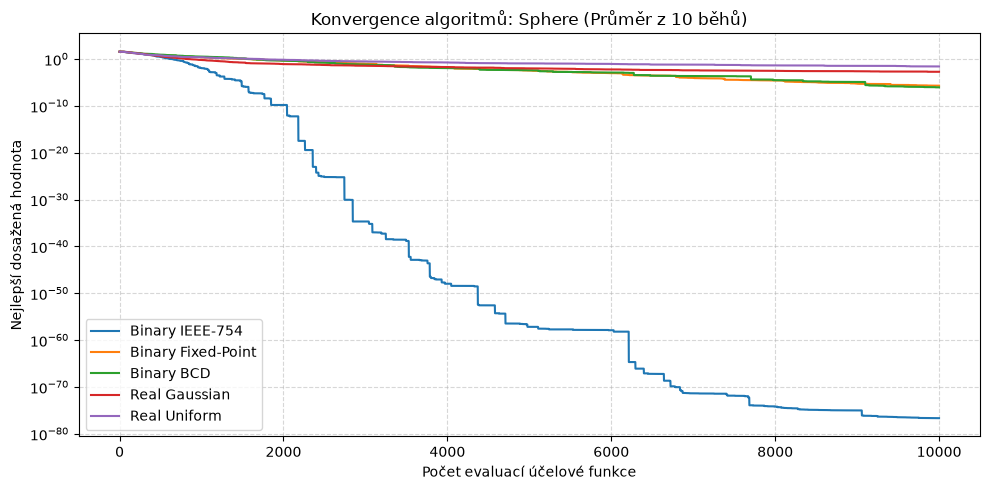

### **Rosenbrock**

| Varianta algoritmu | Nejlepší | Nejhorší | Průměr | Medián | Směrod. odchylka |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Binary IEEE-754** | 8.7560e+00 | 5.7965e+02 | 1.3300e+02 | 5.3157e+01 | 1.7486e+02 |
| **Binary Fixed-Point** | 8.3533e+00 | 1.0663e+02 | 5.3941e+01 | 5.6354e+01 | 2.7873e+01 |
| **Binary BCD** | 1.4396e+01 | 2.2976e+02 | 1.0467e+02 | 8.2827e+01 | 8.6131e+01 |
| **Real Gaussian** | 5.3007e+00 | 3.4723e+01 | 1.2045e+01 | 8.3408e+00 | 8.6275e+00 |
| **Real Uniform** | 1.2925e+01 | 9.3190e+01 | 4.3549e+01 | 1.8044e+01 | 3.4195e+01 |


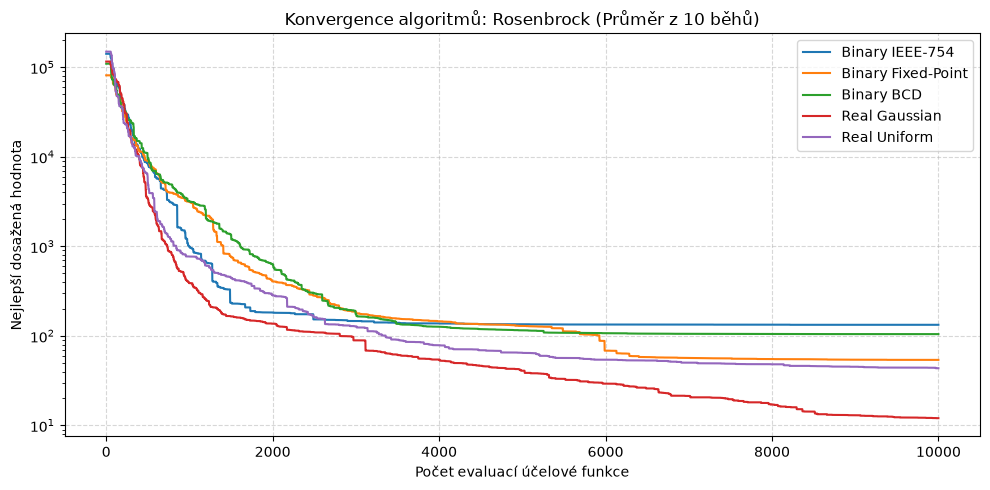

### **Schwefel**

| Varianta algoritmu | Nejlepší | Nejhorší | Průměr | Medián | Směrod. odchylka |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Binary IEEE-754** | 3.3763e+02 | 9.9349e+02 | 6.5161e+02 | 6.3250e+02 | 2.2483e+02 |
| **Binary Fixed-Point** | 1.4925e+01 | 5.5861e+02 | 3.5990e+02 | 4.1593e+02 | 1.6428e+02 |
| **Binary BCD** | 2.2664e+02 | 5.6267e+02 | 4.4266e+02 | 4.5949e+02 | 1.0759e+02 |
| **Real Gaussian** | 2.3232e+00 | 7.1249e+02 | 3.2186e+02 | 3.5711e+02 | 1.9852e+02 |
| **Real Uniform** | 3.7880e+00 | 3.3926e+01 | 1.7401e+01 | 1.4103e+01 | 9.2000e+00 |


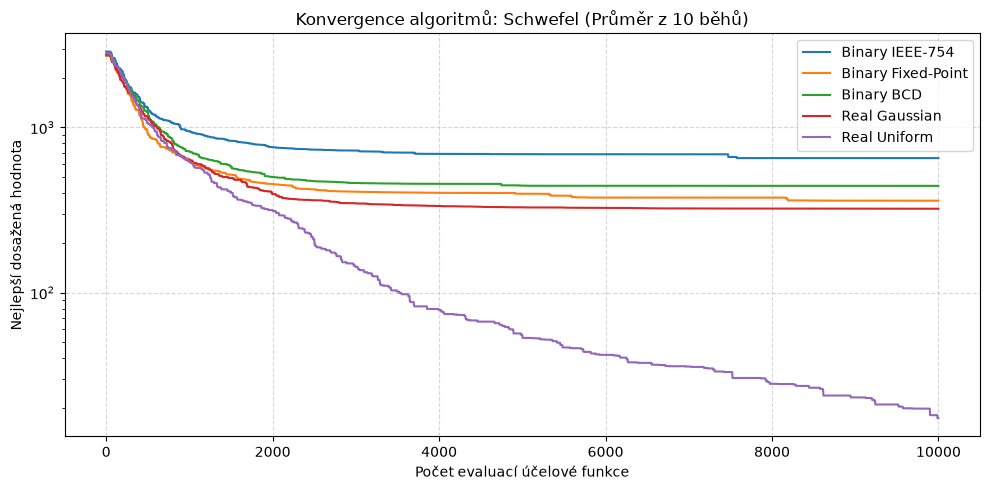

In [10]:
def display_results(stats, curves):
    for func_name in BENCHMARK_FUNCTIONS.keys():
        md = f"### **{func_name}**\n\n"
        md += "| Varianta algoritmu | Nejlepší | Nejhorší | Průměr | Medián | Směrod. odchylka |\n"
        md += "| :--- | :--- | :--- | :--- | :--- | :--- |\n"
        
        for var_name, s in stats[func_name].items():
            md += f"| **{var_name}** | {s['Best']:.4e} | {s['Worst']:.4e} | {s['Mean']:.4e} | {s['Median']:.4e} | {s['Std']:.4e} |\n"
        
        display(Markdown(md))
        
        # Convergence Curves
        plt.figure(figsize=(10, 5))
        for var_name, curve in curves[func_name].items():
            # Apply log scale for Y-axis because differences can span several orders of magnitude
            plt.plot(curve, label=var_name, linewidth=1.5)
            
        plt.title(f"Konvergence algoritmů: {func_name} (Průměr z 10 běhů)")
        plt.xlabel("Počet evaluací účelové funkce")
        plt.ylabel("Nejlepší dosažená hodnota")
        plt.yscale("log")
        plt.grid(True, linestyle="--", alpha=0.5)
        plt.legend()
        plt.tight_layout()
        plt.show()

display_results(experiment_stats, experiment_curves)

## **Závěr a zhodnocení experimentů**

Výsledky experimentů na třech odlišných testovacích funkcích jasně ukazují, že neexistuje "jeden univerzálně nejlepší" algoritmus. Volba reprezentace a mutace musí odpovídat charakteru řešeného problému.

### Zhodnocení podle testovacích funkcí:

*   **Sphere:**
    *   Nejlepšího výsledku dosáhla varianta **Binary IEEE-754** (nejlepší hodnota v řádu $10^{-83}$).
    *   **Důvod:** Globální minimum funkce Sphere leží přesně v bodě $0.0$. Ve standardu IEEE-754 je hodnota $0.0$ reprezentována jako řetězec samých nul. Algoritmus tak v podstatě řeší triviální problém (ekvivalent Zero-Max), kdy ho "tlačíme" k vymazání všech jedniček. Reálné reprezentace (Gaussian i Uniform) konvergují spolehlivě (v řádech $10^{-3}$ až $10^{-4}$), ale nedosahují takto extrémní přesnosti, protože se k nule přibližují reálnými matematickými kroky.

*   **Rosenbrock:**
    *   Nejlepším a nejstabilnějším algoritmem zde byl **Real Gaussian** (průměr $12.045$, nejlepší výsledek $5.30$).
    *   **Důvod:** Nalezení optima u Rosenbrockovy funkce vyžaduje jemné, inkrementální posuny podél úzkého údolí. Gaussova mutace přesně toto umožňuje – dělá malé lokální kroky. Binární reprezentace (včetně IEEE-754) zde selhávají (průměr $133.00$ u IEEE-754), protože trpí na tzv. "Hammingovy útesy". Změna jediného bitu může znamenat obrovský skok v reálné hodnotě, což jedince "vyhodí" z údolí ven.

*   **Schwefel (Vysoce multimodální, mnoho lokálních minim):**
    *   Z hlediska robustnosti byla jasně nejlepší **Real Uniform** (nejlepší průměr $17.401$ a nejnižší "nejhorší" výsledek $33.926$). Varianta **Real Gaussian** dokázala sice nalézt absolutně nejlepší jednorázové optimum ($2.32$), ale s obrovským rozptylem a občasným uváznutím ve špatném lokálním minimu (až $712.49$).
    *   **Důvod:** Schwefelova funkce vyžaduje silnou exploraci (prozkoumávání) napříč celým prostorem, protože lokální minima jsou velmi hluboká a daleko od sebe. Uniformní mutace toto zajišťuje absolutními skoky na náhodné nové hodnoty. Binární IEEE-754 opět propadá (průměr $651.61$), neboť mutace v exponentu způsobuje příliš chaotické a nekontrolovatelné skoky.

### Celkové shrnutí:
1.  **Binární kódování (IEEE-754, Fixed-Point, BCD):** Pro spojitou optimalizaci je většinou **nevhodné**. Je náchylné na Hammingovy útesy a mutace neodpovídá metrice reálného prostoru (změna bitu může znamenat posun o $0.001$ i o $1000$). Úspěch u Sphere funkce je pouze anomálií danou specifikou bodu $0.0$.
2.  **Real-valued kódování:** Je pro spojitou optimalizaci mnohem přirozenější a efektivnější.
3.  **Gaussova mutace** je ideální pro lokální dolaďování (exploitation) v hladkých prostorech (Rosenbrock).
4.  **Uniformní mutace** je klíčová pro únik z lokálních minim a globální prohledávání (exploration) u multimodálních funkcí (Schwefel).

## **Autor úkolu**
* Martin Koňařík m1_konarik@utb.cz

*Vytvořeno v rámci předmětu AP9EV na FAI UTB v roce 2026*